# D2 · In Vivo Contrast Mechanisms

**Part:** D – Contrast · **Reading time:** ~75 min · **Pass 1 overview:** [P1.4 Contrast and Image Quality](../pass1_big_picture/P1.4_Contrast_and_Image_Quality.ipynb) · **Refreshers you may want:** [RM2 Complex numbers and rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [RM3 Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [RM5 Fourier pairs and sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)

**Why this chapter matters.** Real tissue is not a uniform bottle of water with a $T_1$ and a $T_2$. Inside the body the magnetic field varies on microscopic and macroscopic scales (blood, iron, air–tissue interfaces), hydrogen sits in two very different molecules (water and fat) that resonate at different frequencies, and we can inject drugs that change relaxation. Each of these effects is a nuisance in some scans and *the* source of contrast in others: $T_2^*$ and susceptibility-weighted imaging (SWI) for veins and bleeds, BOLD for functional MRI, Dixon imaging for fat quantification, fat suppression for almost every musculoskeletal and abdominal exam, and gadolinium for tumours and inflammation.

## Learning goals

1. Describe how various types of MRI contrast are created
    * Describe the mechanisms that create susceptibility contrast
    * Describe the mechanisms that create $T_2^*$ relaxation
    * Describe how fat/water imaging works
    * Describe how Gd-based contrast agents work
2. *(added)* Derive why a Lorentzian distribution of off-resonance gives an exponential ($T_2^*$) decay, and what other distributions give
3. *(added)* Compute in-phase / out-of-phase echo times and implement a two-point Dixon separation, including its failure modes
4. *(added)* Compare spectral fat saturation, STIR, water excitation and Dixon for fat suppression
5. *(added)* Compute $T_1$/$T_2$ and signal changes from contrast-agent relaxivity and concentration

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $B_0$ | main magnetic field | T | 1.5 T, 3 T |
| $\Delta B_0(\vec r)$ | local deviation of the static field from $B_0$ | T | ppm of $B_0$ |
| $\bar\gamma$ | gyromagnetic ratio $\gamma/2\pi$ | Hz/T | 42.58 MHz/T |
| $f_0=\bar\gamma B_0$ | Larmor frequency | Hz | 63.9 MHz @1.5 T, 127.7 MHz @3 T |
| $\Delta f_r(\vec r)=\bar\gamma\Delta B_0(\vec r)$ | off-resonance due to field inhomogeneity | Hz | 0–100s of Hz |
| $\Delta f_{cs}$ | chemical-shift frequency offset | Hz | fat: −223 Hz @1.5 T, −447 Hz @3 T |
| $\delta_{cs}$ | chemical shift in ppm (dimensionless × 10⁻⁶) | – (ppm) | fat −3.5 ppm; **not** the resolution $\delta$ |
| $\sigma$ | chemical shielding constant | – | ~10⁻⁶ |
| $\chi$, $\Delta\chi$ | magnetic (volume) susceptibility; difference between two materials | – (SI) | water −9.05 ppm; air ≈ +0.36 ppm |
| $M_{xy}=M_x+iM_y$ | transverse magnetization (rotating frame) | normalized | |
| $M_0$ | equilibrium magnetization | normalized | |
| $m(\vec r)$, $m_{water}$, $m_{fat}$ | image (transverse magnetization at TE); its water and fat parts | a.u. | |
| $s(t)$ | signal | a.u. | |
| $\phi$ | phase of $M_{xy}$ or of an image pixel | rad | |
| $T_2$, $T_2^*$, $T_2'$ | transverse, effective transverse, inhomogeneity-dephasing time constants | s | $1/T_2^*=1/T_2+1/T_2'$ |
| $R_2^*=1/T_2^*$, $R_2'=1/T_2'$ | corresponding rates | s⁻¹ | |
| $p(\Delta f)$ | probability density of off-resonance within a voxel | 1/Hz | |
| $\Gamma$ | half-width at half-maximum of a Lorentzian $p(\Delta f)$ | Hz | $1/T_2'=2\pi\Gamma$ |
| $\sigma_f$ | standard deviation of a Gaussian $p(\Delta f)$ | Hz | |
| $W$ | full width of a uniform $p(\Delta f)$ | Hz | |
| $TE$, $TE_{IP}$, $TE_{OP}$ | echo time; in-phase and out-of-phase echo times | s | 2.2 / 4.5 ms @1.5 T |
| $TR$, $TI$, $\theta$ | repetition time, inversion time, flip angle | s, s, rad | |
| $FF$ | (proton-density) fat fraction $m_{fat}/(m_{water}+m_{fat})$ | – | liver steatosis: > 5 % |
| $r_1$, $r_2$ | relaxivities of a contrast agent | L mmol⁻¹ s⁻¹ (= mM⁻¹ s⁻¹) | Gd chelates ≈ 3–5 @1.5 T |
| $C$ (or [CM]) | contrast-agent concentration | mmol/L (mM) | tissue 0.1–1 mM; first-pass blood up to ~5–10 mM |
| $\hat T_1$, $\hat T_2$ | relaxation times with agent present | s | |
| $Y$ | blood oxygen saturation | – | arterial ≈ 0.98, venous ≈ 0.6 |
| $b$, $D$ | diffusion weighting factor; diffusion coefficient | s/mm², mm²/s | $b$ = 1000 s/mm²; $D_{water,37°C}\approx3\times10^{-3}$ mm²/s |

> **⚠️ Common confusion:** the letter $\delta$ is used for the chemical shift (ppm) in this chapter, but for spatial resolution elsewhere. And $\sigma$ here is the shielding constant (or the width of a Gaussian, $\sigma_f$), not the noise level.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Off-resonance and chemical shift

### Off-resonance

Ideally the field is perfectly uniform (apart from the gradients we switch on deliberately). In practice there are unavoidable variations $\Delta B_0(\vec r)$, which shift the local resonance frequency:

$$\Delta f_r(\vec r)=\bar\gamma\,\Delta B_0(\vec r).$$

*In words:* a field error of $\Delta B_0$ tesla changes the precession frequency by $\bar\gamma\Delta B_0$ hertz,
where $\bar\gamma=42.58$ MHz/T for ¹H. Example: 1 ppm of 3 T is 3 µT, i.e. $\Delta f_r=127.7$ Hz.

These variations have two origins: imperfections of the magnet (reduced by shimming, see [B3 Main Magnet Engineering](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb)) and, mostly, the **patient**: tissues have slightly different **magnetic susceptibility** $\chi$, i.e. they magnetize slightly differently in $B_0$ and distort the field around them. The largest offender is the air–tissue interface ($\Delta\chi\approx 9.4$ ppm) near the sinuses, ear canals and bowel, which can create offsets of several ppm.

### Chemical shift

The electrons around a nucleus partially **shield** it from $B_0$: the nucleus feels $B_0(1-\sigma)$ with a shielding constant $\sigma$ that depends on the chemical environment. Relative to water, this gives a frequency offset

$$\Delta f_{cs}=\delta_{cs}\,\bar\gamma B_0 .$$

*In words:* the chemical shift scales linearly with field strength,
where $\delta_{cs}$ is the shift in parts per million (ppm, i.e. units of $10^{-6}$) and $\Delta f_{cs}$ the frequency offset in Hz. For the main fat peak (methylene, –CH₂–) $\delta_{cs}\approx-3.5$ ppm: fat precesses **slower** than water, by 223 Hz at 1.5 T and 447 Hz at 3 T (the original text quotes the rounded values 220/440 Hz).

In [2]:
# Fat-water chemical shift and the corresponding in-phase / out-of-phase echo times
print(f"{'B0 [T]':>6s} {'f0 [MHz]':>9s} {'fat shift [Hz]':>15s} {'1st OP TE [ms]':>15s} {'1st IP TE [ms]':>15s}")
for B0 in [0.55, 1.5, 3.0, 7.0]:
    dfcs = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)          # negative: fat slower than water
    print(f"{B0:6.2f} {mt.larmor_frequency(B0)/1e6:9.1f} {dfcs:15.0f} "
          f"{0.5/abs(dfcs)*1e3:15.2f} {1/abs(dfcs)*1e3:15.2f}")

B0 [T]  f0 [MHz]  fat shift [Hz]  1st OP TE [ms]  1st IP TE [ms]
  0.55      23.4             -82            6.10           12.20
  1.50      63.9            -224            2.24            4.47
  3.00     127.7            -447            1.12            2.24
  7.00     298.0           -1043            0.48            0.96


*Interpretation:* at 1.5 T fat and water are opposed at TE ≈ 2.2 ms and aligned at 4.5 ms; at 3 T everything happens twice as fast (1.1 / 2.2 ms). These numbers will reappear in Dixon imaging (Section 5).

## 2. Susceptibility-induced contrasts

Differences in susceptibility between tissues create differences in the local field and therefore in resonance frequency. This can be used in two ways: through the **phase** of the image, and through the extra signal **decay** ($T_2^*$) caused by the spread of frequencies inside a voxel.

### 2.1 Phase contrast

Off-resonant transverse magnetization precesses faster or slower than the rotating frame. With our sign convention ($M_{xy}(t)=M_{xy}(0)e^{-i2\pi\Delta f t}$, see [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)), at the echo time it has acquired the phase

$$\phi(\vec r)=-2\pi\,\Delta f_r(\vec r)\,TE.$$

*In words:* the phase grows linearly with the off-resonance and with TE,
where $\phi$ is in radians, $\Delta f_r$ in Hz and TE in seconds. Example: a 0.05 ppm field change at 3 T (6.4 Hz) gives 0.8 rad at TE = 20 ms – easily measurable.

To use phase as **susceptibility contrast**, all other sources of phase must be removed: large-scale field imperfections of the magnet and of the head shape ("background field"), chemical shift, and the phase of the RF coils. In practice this is done by high-pass filtering the phase image or by more sophisticated background-field removal; the result is the basis of SWI (Section 3) and of quantitative susceptibility mapping (QSM).

### 2.2 $T_2^*$: dephasing inside a voxel

Ideally the signal would decay with $T_2$. But every voxel contains a range of off-resonance frequencies, and the measured signal is the **sum** (integral) of all transverse magnetization in the voxel:

$$s_{voxel}(t)=\int_{voxel}M_{xy}(\vec r,0)\,e^{-t/T_2(\vec r)}\,e^{-i2\pi\Delta f_r(\vec r)\,t}\,d\vec r\;\approx\;M_{xy,voxel}(0)\,e^{-t/T_2^*}.$$

*In words:* each part of the voxel decays with $T_2$ **and** rotates at its own frequency; when the rotating phasors are added they partially cancel, so the sum decays faster than $T_2$. That faster decay is summarized by one number, $T_2^*$,
where $\vec r$ runs over the voxel and $\Delta f_r(\vec r)$ is the local off-resonance in Hz. (The original wrote the phase factor without the $t$; the phase must grow with time. Effects of the imaging gradients are removed by the reconstruction and are left out here.)

The mechanism – **dephasing** – is shown in the original book's animations (made with `t2star_spinecho_illustration.m`, ported to Python below): 64 isochromats in one voxel, $T_2$ = 80 ms, Gaussian spread of off-resonance.

![Voxel signal decay, no off-resonance](../images/t2star_no_off-resonance.gif)

**No off-resonance, $T_2$ = 80 ms**

![Voxel signal decay, mild off-resonance](../images/t2star_mild_off-resonance.gif)

**Mild off-resonance (0.07 ppm at 1.5 T), $T_2$ = 80 ms**

![Voxel signal decay, severe off-resonance](../images/t2star_severe_off-resonance.gif)

**Severe off-resonance (0.25 ppm at 1.5 T), $T_2$ = 80 ms**

$T_2^*$ is an approximation of these dephasing effects and depends on voxel size and location. It is conventionally split into the intrinsic $T_2$ and an extra dephasing rate $1/T_2'$:

$$\frac{1}{T_2^*}=\frac{1}{T_2}+\frac{1}{T_2'},\qquad T_2^*\le T_2 .$$

*In words:* decay **rates** add (not times): the irreversible microscopic rate $1/T_2$ plus the rate $1/T_2'$ from static field variation across the voxel,
where $T_2'$ is the inhomogeneity time constant (s).

The next cell is the Python port of `t2star_spinecho_illustration.m` (without the spin echo, which is the topic of [D3](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)). We show snapshots instead of an animation: the arrows are the 8×8 isochromats' $M_{xy}$, and the right panel is the voxel-averaged signal.

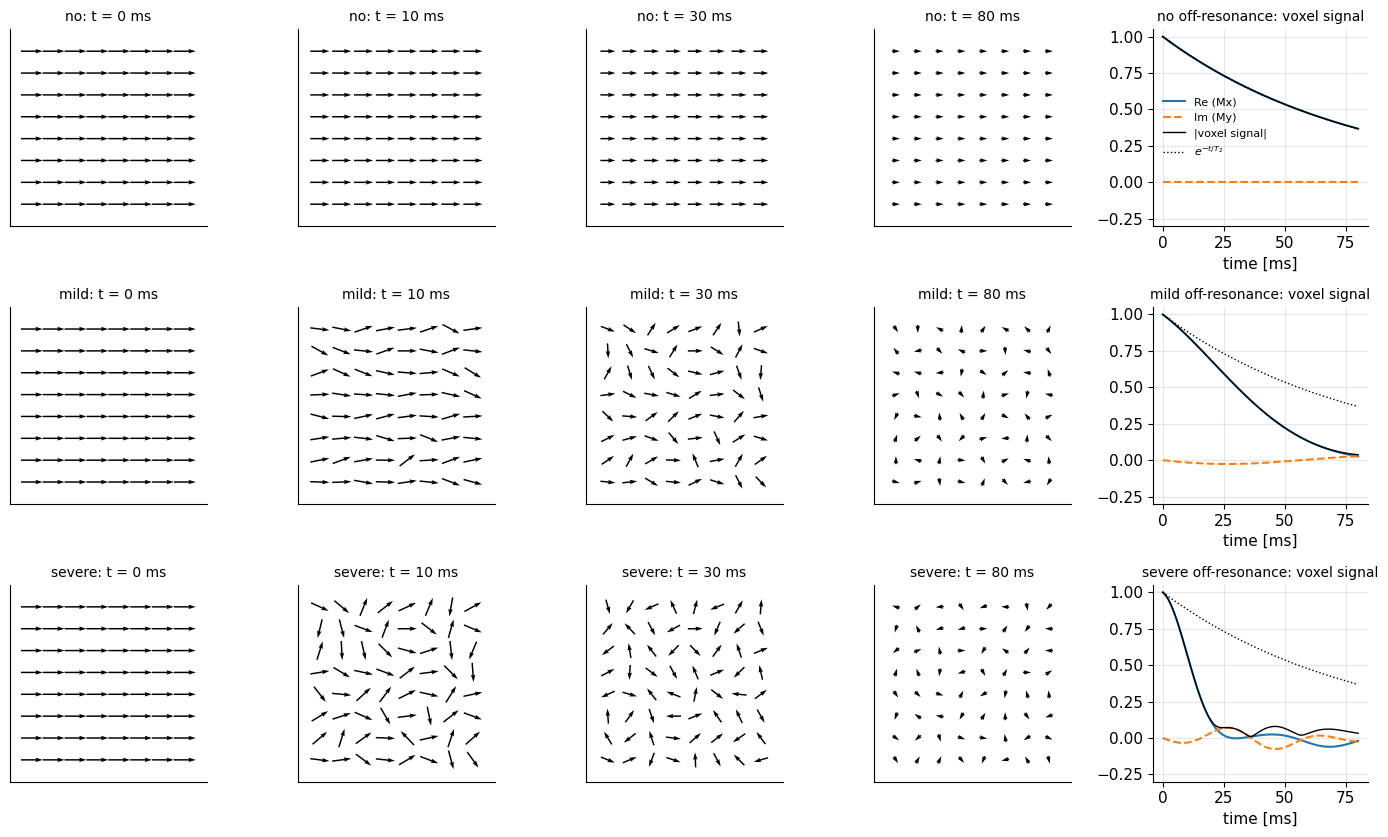

In [3]:
# Port of t2star_spinecho_illustration.m (no spin echo): 64 isochromats, Gaussian off-resonance spread
B0, T2 = 1.5, 0.080                       # [T], [s]
rng = np.random.default_rng(0)
n_side = 8; Ns = n_side**2
dt, Tmax = 0.5e-3, 0.080                   # time step and duration [s]
n_steps = int(round(Tmax / dt))
cases = {"no": 0.0, "mild": 0.07e-6, "severe": 0.25e-6}   # std of dB0/B0 (dimensionless; 1e-6 = 1 ppm)
z = rng.standard_normal(Ns)                 # same random pattern for all cases
snap_times = [0, 0.010, 0.030, 0.080]       # [s]

fig, axs = plt.subplots(3, 5, figsize=(14, 8.5))
for row, (name, rel) in enumerate(cases.items()):
    df = mt.GAMMA_BAR * B0 * rel * z           # off-resonance of each isochromat [Hz]
    t, M = mt.bloch_simulate(n_steps=n_steps, dt=dt, M_init=[1, 0, 0], T2=T2, df=df)   # start after 90 deg
    Mxy = M[:, :, 0] + 1j * M[:, :, 1]
    gx, gy = np.meshgrid(np.arange(n_side), np.arange(n_side))
    for col, ts in enumerate(snap_times):
        k = int(round(ts / dt)); m = Mxy[k].reshape(n_side, n_side)
        ax = axs[row, col]
        ax.quiver(gx - m.real / 2, gy - m.imag / 2, m.real, m.imag, angles="xy", scale_units="xy", scale=1)
        ax.set_xlim(-1, n_side); ax.set_ylim(-1, n_side); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{name}: t = {ts*1e3:.0f} ms", fontsize=10)
    s = Mxy.mean(axis=1)
    ax = axs[row, 4]
    ax.plot(t * 1e3, s.real, label="Re (Mx)"); ax.plot(t * 1e3, s.imag, "--", label="Im (My)")
    ax.plot(t * 1e3, np.abs(s), "k", lw=1, label="|voxel signal|")
    ax.plot(t * 1e3, np.exp(-t / T2), "k:", lw=1, label="$e^{-t/T_2}$")
    ax.set_ylim(-0.3, 1.05); ax.set_xlabel("time [ms]"); ax.set_title(f"{name} off-resonance: voxel signal", fontsize=10)
    if row == 0: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

*Interpretation:* without off-resonance all arrows shrink together (pure $T_2$); with mild spread they fan out and the voxel signal falls below the $T_2$ curve; with severe spread the arrows point every which way after ~30 ms and the voxel signal is essentially gone even though each individual isochromat still has a sizeable $|M_{xy}|$.

### 2.3 Why "exponential"? The distribution of frequencies decides the decay shape

Write the voxel as a collection of isochromats with off-resonance $\Delta f$ distributed with probability density $p(\Delta f)$ (units 1/Hz, $\int p\,d\Delta f=1$). If $T_2$ is the same everywhere,

$$s(t)=M_{xy}(0)\,e^{-t/T_2}\int p(\Delta f)\,e^{-i2\pi\Delta f\,t}\,d\Delta f
= M_{xy}(0)\,e^{-t/T_2}\;P(t).$$

*In words:* the extra decay $P(t)$ is the **Fourier transform of the frequency distribution** (see [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb)): a wide distribution gives a fast decay, a narrow one a slow decay,
where $P(t)=\mathcal F\{p\}(t)$, with $t$ playing the role of the "frequency" variable.

So the decay is exponential only for one special distribution:

| distribution $p(\Delta f)$ | $P(t)$ | decay shape |
|---|---|---|
| **Lorentzian**, half-width $\Gamma$: $\dfrac{1}{\pi}\dfrac{\Gamma}{\Gamma^2+\Delta f^2}$ | $e^{-2\pi\Gamma\,|t|}$ | **exponential** ⇒ $1/T_2'=2\pi\Gamma$ |
| Gaussian, std $\sigma_f$ | $e^{-2\pi^2\sigma_f^2t^2}$ | Gaussian (slow start, then fast) |
| uniform, width $W$ (e.g. linear field gradient across the voxel) | $\mathrm{sinc}(Wt)=\dfrac{\sin\pi Wt}{\pi Wt}$ | sinc, with zeros at $t=k/W$ |

<details><summary><b>📐 Derivation (optional): Lorentzian ↔ exponential</b></summary>

It is easiest to go the other way: compute the FT of the two-sided exponential $g(t)=e^{-a|t|}$ ($a>0$):
$$\int_{-\infty}^{\infty}e^{-a|t|}e^{-i2\pi ft}\,dt=\int_0^\infty e^{-(a+i2\pi f)t}dt+\int_0^\infty e^{-(a-i2\pi f)t}dt
=\frac{1}{a+i2\pi f}+\frac{1}{a-i2\pi f}=\frac{2a}{a^2+4\pi^2f^2}.$$
With $a=2\pi\Gamma$ this is $\dfrac{4\pi\Gamma}{4\pi^2(\Gamma^2+f^2)}=\dfrac{1}{\pi}\dfrac{\Gamma}{\Gamma^2+f^2}$, exactly the normalized Lorentzian $p(f)$. By the Fourier inversion theorem, $\int p(f)e^{+i2\pi ft}df=e^{-2\pi\Gamma|t|}$, and because $p$ is even the sign of the exponent does not matter. Hence $P(t)=e^{-2\pi\Gamma t}$ for $t\ge0$, and
$$\frac{1}{T_2^*}=\frac{1}{T_2}+2\pi\Gamma .$$
The Gaussian and sinc results follow from the standard pairs in [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb).

Physically, the field around many randomly placed small magnetic perturbers (e.g. iron particles, red cells) produces a distribution with Lorentzian-like tails (Yablonskiy & Haacke 1994), which is why the exponential $T_2^*$ model works reasonably well in tissue at not-too-short times.

</details>

The simulation below adds 20 000 random phasors for each distribution (all with the same width parameter 10 Hz) and compares with the analytic $P(t)$.

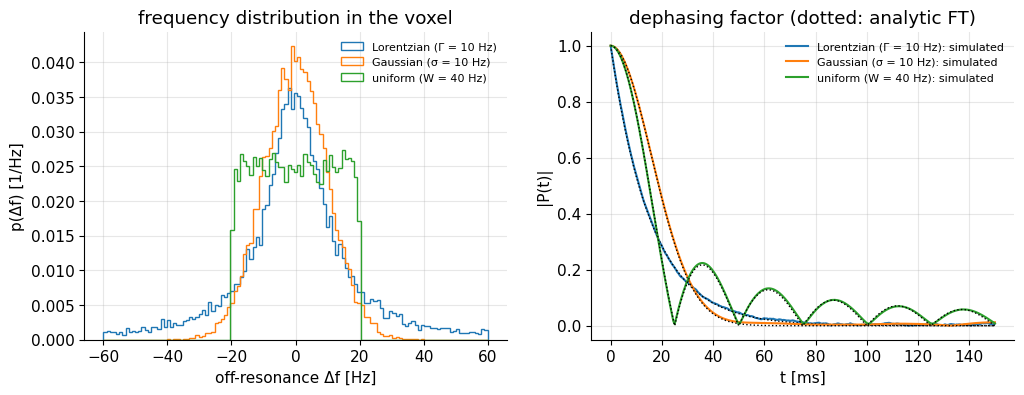

In [4]:
# Monte-Carlo voxel signal for Lorentzian, Gaussian and uniform off-resonance distributions
rng = np.random.default_rng(1)
Ns, w = 20000, 10.0                      # isochromats; width parameter [Hz]
t = np.linspace(0, 0.15, 301)            # [s]
dists = {
    f"Lorentzian (Γ = {w:.0f} Hz)":   (w * rng.standard_cauchy(Ns),        np.exp(-2 * np.pi * w * t)),
    f"Gaussian (σ = {w:.0f} Hz)":     (w * rng.standard_normal(Ns),        np.exp(-2 * np.pi**2 * w**2 * t**2)),
    f"uniform (W = {4*w:.0f} Hz)":    (4 * w * (rng.random(Ns) - 0.5),     np.sinc(4 * w * t)),
}
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for i, (name, (df, P)) in enumerate(dists.items()):
    s = np.exp(-1j * 2 * np.pi * np.outer(t, df)).mean(axis=1)       # phasor sum (no T2 here)
    axs[0].hist(df, bins=121, range=(-60, 60), density=True, histtype="step", color=f"C{i}", label=name)
    axs[1].plot(t * 1e3, np.abs(s), color=f"C{i}", label=f"{name}: simulated")
    axs[1].plot(t * 1e3, np.abs(P), "k:", lw=1)
axs[0].set_xlabel("off-resonance Δf [Hz]"); axs[0].set_ylabel("p(Δf) [1/Hz]"); axs[0].set_title("frequency distribution in the voxel")
axs[0].legend(fontsize=8)
axs[1].set_xlabel("t [ms]"); axs[1].set_ylabel("|P(t)|"); axs[1].set_title("dephasing factor (dotted: analytic FT)")
axs[1].legend(fontsize=8); plt.show()

*Interpretation:* only the Lorentzian gives a straight exponential (a straight line on a log plot); the Gaussian starts flat and then drops fast, and a uniform spread (as produced by a linear field gradient across the voxel) gives a sinc with a complete null at $t=1/W$ = 25 ms followed by small revivals.

### 2.4 $T_2^*$ depends on voxel size – an engineering consequence

A smooth background gradient $G_{bg}$ of the field across a voxel of thickness $\Delta z$ produces a uniform frequency spread of width $W=\bar\gamma\,G_{bg}\,\Delta z$, i.e. a sinc-shaped decay with its first zero at $t=1/W$. Thinner slices (or smaller voxels) therefore lose less signal – the standard remedy for signal voids near the sinuses in gradient-echo and EPI scans.

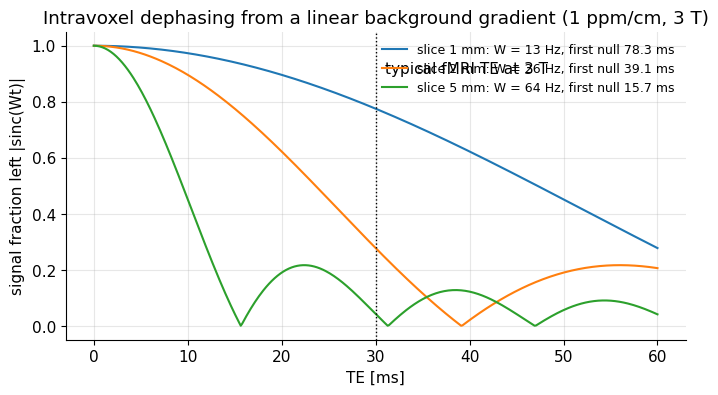

In [5]:
# Through-slice dephasing from a background gradient of 1 ppm/cm at 3 T (near the frontal sinus)
B0 = 3.0
G_bg = 1e-6 * B0 / 0.01                  # field gradient [T/m]: 1 ppm of B0 per cm
t = np.linspace(0, 0.06, 400)
plt.figure()
for dz in [1e-3, 2e-3, 5e-3]:
    W = mt.GAMMA_BAR * G_bg * dz          # frequency spread across the slice [Hz]
    plt.plot(t * 1e3, np.abs(np.sinc(W * t)), label=f"slice {dz*1e3:.0f} mm: W = {W:.0f} Hz, first null {1e3/W:.1f} ms")
plt.axvline(30, color="k", ls=":", lw=1); plt.text(31, 0.9, "typical fMRI TE at 3 T")
plt.xlabel("TE [ms]"); plt.ylabel("signal fraction left |sinc(Wt)|"); plt.legend(fontsize=9)
plt.title("Intravoxel dephasing from a linear background gradient (1 ppm/cm, 3 T)")
plt.show()

*Interpretation:* with a 5 mm slice the signal is already gone by TE ≈ 16 ms, while a 1 mm slice keeps most of it at TE = 30 ms. This is why susceptibility artefacts get worse with thick slices, long TE and high $B_0$.

> **🔧 Engineering reality:** the scanner fights $T_2'$ with **shimming**: room-temperature shim coils (first- and second-order spherical harmonics, sometimes third) adjust the field for each patient, typically to < 0.1–0.5 ppm over a head. But shim coils can only produce smooth fields; the sharp air–tissue gradients near the sinuses cannot be removed this way. Remedies are thin slices, short TE, spin echoes ([D3](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)), higher readout bandwidth, or local passive shims (e.g. intra-oral pads). See [B3](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb).

### 2.5 $T_2^*$ as a source of contrast

$T_2^*$ includes $T_2$ plus the macroscopic dephasing from local field inhomogeneities. The microscopic dephasing ($T_2$) cannot be refocused; the static macroscopic part ($T_2'$) can be refocused with a spin echo ([D3](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)). Although often an artefact, short $T_2^*$ is also important diagnostic contrast that reflects susceptibility differences:

1. **Iron deposition** (e.g. basal ganglia, liver iron overload, hemosiderin from old bleeds): iron compounds are strongly paramagnetic → short $T_2^*$ (dark on $T_2^*$-weighted GRE). Liver iron is quantified clinically from $R_2^*$ maps.
2. **Calcifications**: calcium is (weakly) diamagnetic, but calcifications also contain few mobile protons and create local field disturbances → short $T_2^*$. Phase (or QSM) can distinguish diamagnetic calcium from paramagnetic iron/blood products – a common clinical question.
3. **Oxygenated vs deoxygenated blood**: oxyhemoglobin is diamagnetic (like tissue), **deoxyhemoglobin is paramagnetic**. Deoxygenated (venous) blood therefore has a shorter $T_2^*$ and creates field disturbances around veins. This is used to image veins (SWI) and is the basis of BOLD functional MRI.

Typical $T_2^*$ values in the brain at 3 T are ≈ 40–60 ms for gray and white matter, much shorter in iron-rich deep gray nuclei and in venous blood (≈ 10–30 ms, depending on oxygenation).

## 3. Susceptibility-weighted imaging (SWI): a synthetic example

**SWI** (Haacke et al. 2004) combines magnitude and *filtered* phase of a high-resolution 3D gradient echo with long TE to make small veins and microbleeds stand out:

1. acquire a complex image $\rho(\vec r)$ with a long TE (≈ 20 ms at 3 T);
2. remove the slowly varying background phase by high-pass filtering: divide $\rho$ by a low-pass filtered copy of itself;
3. turn the filtered phase into a **phase mask** that is 1 for one sign of phase and decreases linearly to 0 at $\pm\pi$ for the other sign (the paramagnetic one);
4. multiply the magnitude by the mask a few times (typically 4) and display a minimum-intensity projection over a few slices.

We simulate a small axial patch of brain with small veins running **parallel to $B_0$** (through the slice). For a long cylinder parallel to $B_0$, the field inside is shifted by $\Delta B=\Delta\chi\,B_0/3$ and the field outside is unchanged (for other orientations a dipole-like pattern appears outside as well). We take $\Delta\chi\approx0.45$ ppm (SI) between venous blood ($Y\approx0.6$) and tissue, an order-of-magnitude value. Veins thinner than a voxel cause partial-volume **phase cancellation** within the voxel – the key SWI effect.

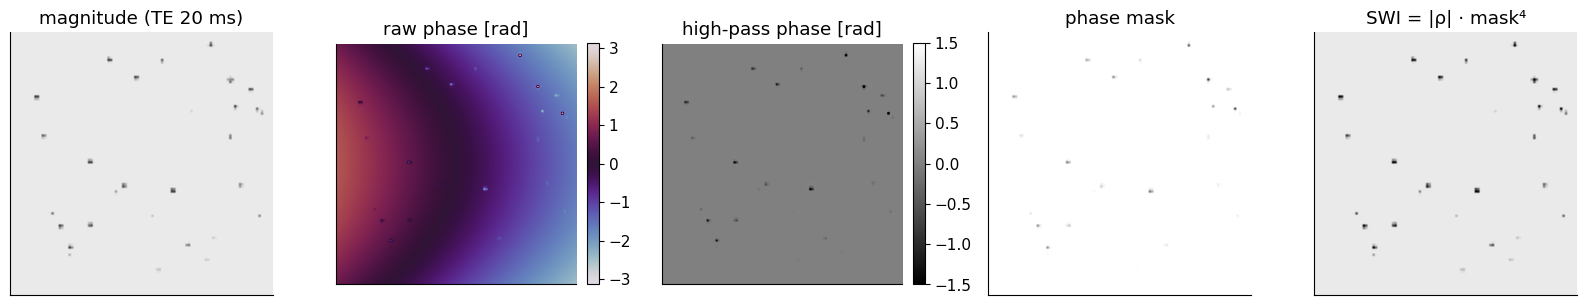

off-resonance inside a vein: 19.2 Hz -> phase -2.41 rad at TE = 20 ms
voxels partly filled by a vein (5-50 %): mean signal drop 31 % in magnitude, 42 % in SWI


In [6]:
# Synthetic SWI: veins parallel to B0 in an axial patch at 3 T, simulated on a fine grid and averaged to voxels
B0, TE = 3.0, 0.020                   # [T], [s]
FOV, N, osf = 0.064, 128, 8            # 6.4 cm patch, 128 voxels (0.5 mm), 8x8 subvoxels per voxel
Nf = N * osf
x = (np.arange(Nf) - Nf / 2) / Nf * FOV
X, Y = np.meshgrid(x, x)
rng = np.random.default_rng(3)
vein = np.zeros((Nf, Nf), bool)
for _ in range(30):                     # random small veins, radius 0.08-0.4 mm (voxel = 0.5 mm)
    xc, yc = rng.uniform(-0.026, 0.026, 2); a = rng.uniform(0.08e-3, 0.4e-3)
    vein |= (X - xc)**2 + (Y - yc)**2 < a**2
dchi = 0.45e-6                          # susceptibility difference venous blood - tissue (SI)
df_vein = mt.GAMMA_BAR * dchi * B0 / 3  # off-resonance inside a vein parallel to B0 [Hz]
df_bg = 15 * (X / FOV * 2) + 10 * (Y / FOV * 2)**2   # smooth background field (shim residual) [Hz]
df = df_bg + df_vein * vein
T2s = np.where(vein, 0.025, 0.045)      # T2* of venous blood / tissue [s] (order of magnitude)
rho_fine = np.where(vein, 0.9, 1.0) * np.exp(-TE / T2s) * np.exp(-1j * 2 * np.pi * df * TE)
rho = rho_fine.reshape(N, osf, N, osf).mean(axis=(1, 3))   # voxel = complex average of subvoxels

# SWI processing
K = mt.fft2c(rho)
k = np.arange(N) - N // 2
win = np.outer(np.hanning(32), np.hanning(32))
Klp = np.zeros_like(K); c = slice(N // 2 - 16, N // 2 + 16); Klp[c, c] = K[c, c] * win
rho_lp = mt.ifft2c(Klp)
phase_hp = np.angle(rho * np.conj(rho_lp))          # high-pass filtered phase [rad]
mask = np.where(phase_hp < 0, 1 + phase_hp / np.pi, 1.0)   # suppress negative phase (paramagnetic, our convention)
swi = np.abs(rho) * mask**4

crop = (slice(10, N - 10), slice(10, N - 10))   # hide FFT edge effects of the non-periodic background field
fig, axs = plt.subplots(1, 5, figsize=(16, 3.6))
mt.show_image(np.abs(rho)[crop], ax=axs[0], title="magnitude (TE 20 ms)", vmin=0, vmax=0.7)
mt.show_image(np.angle(rho)[crop], ax=axs[1], title="raw phase [rad]", cmap="twilight", vmin=-np.pi, vmax=np.pi, colorbar=True)
mt.show_image(phase_hp[crop], ax=axs[2], title="high-pass phase [rad]", cmap="gray", vmin=-1.5, vmax=1.5, colorbar=True)
mt.show_image(mask[crop], ax=axs[3], title="phase mask", vmin=0, vmax=1)
mt.show_image(swi[crop], ax=axs[4], title="SWI = |ρ| · mask⁴", vmin=0, vmax=0.7)
plt.tight_layout(); plt.show()
print(f"off-resonance inside a vein: {df_vein:.1f} Hz -> phase {-2*np.pi*df_vein*TE:.2f} rad at TE = {TE*1e3:.0f} ms")
frac = vein.reshape(N, osf, N, osf).mean(axis=(1, 3))       # vein volume fraction per voxel
bg = np.abs(rho)[frac == 0].mean(); sel = (frac > 0.05) & (frac < 0.5)
print(f"voxels partly filled by a vein (5-50 %): mean signal drop {100*(1-np.abs(rho)[sel].mean()/bg):.0f} % "
      f"in magnitude, {100*(1-swi[sel].mean()/bg):.0f} % in SWI")

*Interpretation:* in the magnitude the larger veins are dark but partially filled voxels lose only part of their signal; the raw phase is dominated by the smooth background field; after high-pass filtering the veins clearly show negative phase, and multiplying by the mask four times makes the veins visibly darker and sharper than in the magnitude (printed numbers: the average drop in partially filled voxels grows from about 30 % to about 40 %, and much more in voxels with larger phase). Amplifying the visibility of small, sub-voxel paramagnetic structures is the point of SWI; real SWI also uses minimum-intensity projections over several slices to connect the vessels.

> **⚠️ Common confusion:** the sign of the phase of paramagnetic structures depends on the vendor's conventions (handedness, conjugation in the reconstruction) and on the vessel orientation. Always calibrate with a known vein before interpreting "positive" or "negative" phase.

## 4. BOLD contrast (functional MRI)

When a brain region becomes active, blood flow increases *more* than oxygen consumption, so venous blood becomes **more oxygenated**: less paramagnetic deoxyhemoglobin → less dephasing → slightly **longer $T_2^*$** → slightly higher signal in a $T_2^*$-weighted gradient echo. This **blood-oxygenation-level-dependent** (BOLD) effect (Ogawa et al. 1990) is a 1–5 % signal change at 3 T.

With a gradient echo $S(TE)=S_0e^{-TE\cdot R_2^*}$ and an activation-induced rate change $\Delta R_2^*<0$:

$$\frac{\Delta S}{S}\approx-TE\,\Delta R_2^*,\qquad \Delta S=S_0\,e^{-TE/T_2^*}\,(-TE\,\Delta R_2^*)\;\Rightarrow\;TE_{opt}=T_2^* .$$

*In words:* the *relative* change grows linearly with TE, but the signal itself decays; the *absolute* change $\propto TE\,e^{-TE/T_2^*}$ is maximal at TE = $T_2^*$ (set the derivative $e^{-TE/T_2^*}(1-TE/T_2^*)$ to zero),
where $S_0$ is the signal at TE = 0, $R_2^*=1/T_2^*$, and $\Delta R_2^*$ is the change on activation (s⁻¹). Hence fMRI at 3 T uses TE ≈ 30 ms, at 7 T ≈ 20–25 ms.

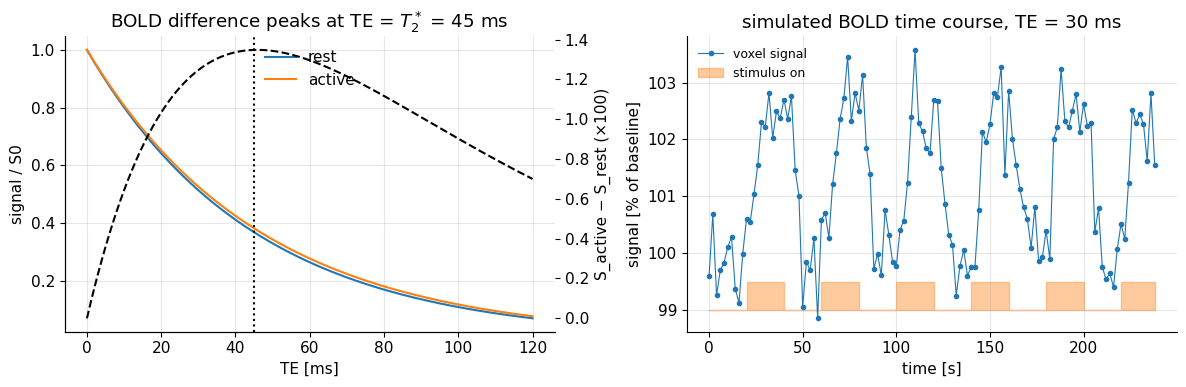

BOLD change at TE = 30 ms: 2.4 %


In [7]:
# BOLD: signal vs TE at rest/activation, and a simulated block-design time course (3 T, gray matter)
T2s_rest = 0.045                   # [s]
dR2s = -0.8                        # change in R2* on activation [1/s] (order of magnitude at 3 T)
TE = np.linspace(0, 0.12, 241)
S_rest = np.exp(-TE / T2s_rest); S_act = np.exp(-TE * (1 / T2s_rest + dR2s))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(TE * 1e3, S_rest, label="rest"); axs[0].plot(TE * 1e3, S_act, label="active")
ax2 = axs[0].twinx(); ax2.plot(TE * 1e3, (S_act - S_rest) * 100, "k--", label="difference ×100"); ax2.grid(False)
ax2.axvline(T2s_rest * 1e3, color="k", ls=":"); ax2.set_ylabel("S_active − S_rest (×100)")
axs[0].set_xlabel("TE [ms]"); axs[0].set_ylabel("signal / S0"); axs[0].legend(loc="upper center")
axs[0].set_title(f"BOLD difference peaks at TE = $T_2^*$ = {T2s_rest*1e3:.0f} ms")

# block design: 20 s off / 20 s on, TR = 2 s, simple gamma-shaped hemodynamic response
TR, n_vol = 2.0, 120
tt = np.arange(n_vol) * TR
stim = ((tt // 20) % 2 == 1).astype(float)
th = np.arange(0, 30, TR); hrf = th**5 * np.exp(-th) ; hrf /= hrf.sum()   # peak ~5 s
resp = np.convolve(stim, hrf)[:n_vol]
TEf = 0.030
sig = np.exp(-TEf * (1 / T2s_rest + dR2s * resp))
sig = sig / np.exp(-TEf / T2s_rest) * 100 + rng.normal(0, 0.5, n_vol)   # percent of baseline + 0.5 % noise
axs[1].plot(tt, sig, ".-", lw=0.8, label="voxel signal")
axs[1].fill_between(tt, 99, 99 + stim * 0.5, step="post", color="C1", alpha=0.4, label="stimulus on")
axs[1].set_xlabel("time [s]"); axs[1].set_ylabel("signal [% of baseline]"); axs[1].legend(fontsize=9)
axs[1].set_title(f"simulated BOLD time course, TE = {TEf*1e3:.0f} ms")
plt.tight_layout(); plt.show()
print(f"BOLD change at TE = 30 ms: {100*(np.exp(-TEf*dR2s)-1):.1f} %")

*Interpretation:* the absolute signal difference between rest and activation is largest at TE ≈ $T_2^*$; a ~2.4 % change is visible above 0.5 % noise, delayed and smoothed by the hemodynamic response. Real fMRI also has physiological noise, drift and motion, so many repetitions and statistics are needed.

## 5. Fat/water imaging (Dixon)

The two big sources of ¹H signal in the body are water and the –CH₂– groups in lipids ("fat"). Because of the chemical shift, fat precesses $|\Delta f_{cs}|$ ≈ 223 Hz (1.5 T) / 447 Hz (3 T) slower. In reality lipids have several peaks (a "6-peak model" is common), but here we treat fat as a single peak at −3.5 ppm.

**Dixon methods** (Dixon 1984) acquire images at several echo times and use the phase differences between fat and water to separate them. Ideally, in a gradient echo,

$$s(TE)=\Big(m_{water}(\vec r)+m_{fat}(\vec r)\,e^{-i2\pi\Delta f_{cs}TE}\Big)\,e^{-i2\pi\Delta f_r(\vec r)TE}.$$

*In words:* the pixel value is the water part plus the fat part, which has rotated by $2\pi\Delta f_{cs}TE$ relative to water; both are additionally rotated by the field inhomogeneity,
where $m_{water}$, $m_{fat}$ are real, non-negative water and fat images, $\Delta f_{cs}<0$ the fat shift and $\Delta f_r$ the local off-resonance (Hz). ($T_2^*$ decay is ignored.)

Choose the **in-phase** echo time $TE_{IP}=n/|\Delta f_{cs}|$ (fat has made a whole number of extra turns) and the **out-of-phase** echo time $TE_{OP}=(n+\tfrac12)/|\Delta f_{cs}|$ (half a turn). Without field inhomogeneity ($\Delta f_r=0$):

$$s_{IP}=m_{water}+m_{fat},\qquad s_{OP}=m_{water}-m_{fat}$$

$$\hat m_{water}=\tfrac12\big(s_{IP}+s_{OP}\big),\qquad \hat m_{fat}=\tfrac12\big(s_{IP}-s_{OP}\big).$$

*In words:* in phase, fat and water add; out of phase, they subtract; the sum and difference give back each component. (The original omitted the factor ½.)

![Fat/water imaging illustration: in-phase and out-of-phase images are added and subtracted to give water and fat images; right: two-echo gradient-echo sequence](../images/fat-water-imaging_illustration.png)

*Left: in-phase + out-of-phase = water, in-phase − out-of-phase = fat (abdominal images). Right: a dual-echo gradient-echo sequence acquiring $TE_1$ (out of phase) and $TE_2$ (in phase) after one excitation.*

In practice, $\Delta f_r(\vec r)\neq0$ adds a phase error that must be estimated and removed, and advanced methods (three or more echoes, e.g. IDEAL; multi-peak fat models; $T_2^*$ correction) are needed for robust results and for quantitative **proton-density fat fraction** (PDFF $=m_{fat}/(m_{water}+m_{fat})$), the clinical standard for liver steatosis (> 5 % is abnormal).

### Two-point Dixon on a synthetic phantom

We build water and fat images on the tissue phantom with compartments of different fat fraction (purely synthetic): rim 90 % fat, "lesions" 20 %, one ellipse 60 % (fat-dominant, like bone marrow), everything else 0 %. We then simulate out-of-phase and in-phase echoes at 1.5 T and try three reconstructions:

1. **Complex, ideal field** ($\Delta f_r=0$): the textbook formulas.
2. **Complex, with a smooth field inhomogeneity** of up to ~±60 Hz: the textbook formulas fail.
3. **Magnitude-based** $\big(|s_{IP}|\pm|s_{OP}|\big)/2$: immune to phase errors, but it can only find "the larger" and "the smaller" component → **fat/water swaps** where fat > 50 %.
4. **Simple phase correction**: estimate the field-induced phase difference between the two echoes from $(s_{OP}s_{IP}^*)^2$ (squaring removes the ±π ambiguity due to fat), then apply the formulas. This works if the phase error between echoes is < π/2 (here: $2\pi\cdot60\,\text{Hz}\cdot2.2\,\text{ms}\approx0.8$ rad).

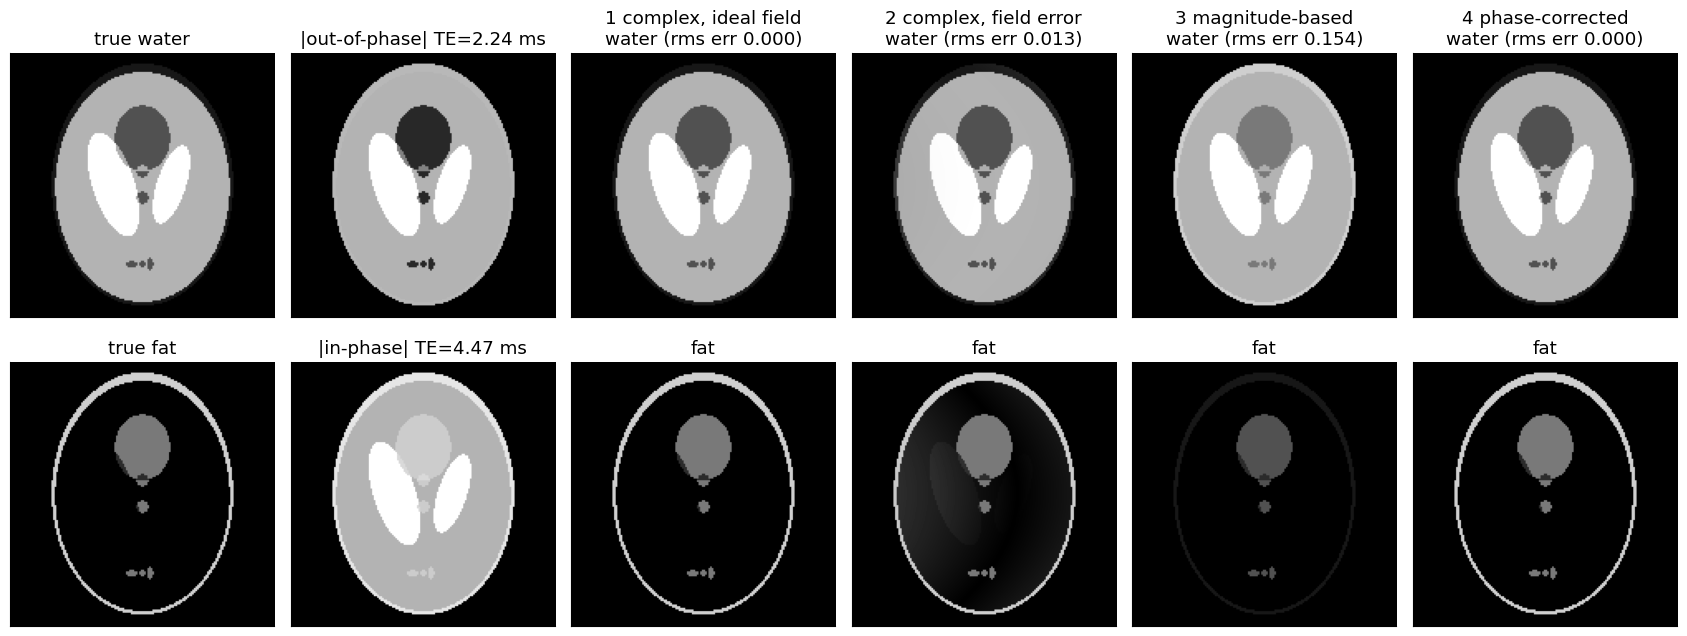

In [8]:
# Two-point Dixon on a synthetic phantom at 1.5 T
ph = mt.tissue_phantom(160)
lab, M0 = ph["labels"], ph["M0"]
FF = np.zeros_like(M0)
FF[lab == 1] = 0.9; FF[lab == 5] = 0.2; FF[lab == 3] = 0.6          # synthetic fat fractions
m_fat, m_water = M0 * FF, M0 * (1 - FF)

B0 = 1.5
dfcs = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)            # [Hz], negative
TE_OP, TE_IP = 0.5 / abs(dfcs), 1.0 / abs(dfcs)      # [s]
yy, xx = np.mgrid[-1:1:160j, -1:1:160j]
dfr = 40 * xx + 25 * yy**2 - 10                      # smooth off-resonance map [Hz]

def echo(TE, dfr):
    return (m_water + m_fat * np.exp(-1j * 2 * np.pi * dfcs * TE)) * np.exp(-1j * 2 * np.pi * dfr * TE)

recon = {}
s_op, s_ip = echo(TE_OP, 0 * dfr), echo(TE_IP, 0 * dfr)
recon["1 complex, ideal field"] = ((s_ip + s_op) / 2, (s_ip - s_op) / 2)
s_op, s_ip = echo(TE_OP, dfr), echo(TE_IP, dfr)
recon["2 complex, field error"] = ((s_ip + s_op) / 2, (s_ip - s_op) / 2)
recon["3 magnitude-based"] = ((np.abs(s_ip) + np.abs(s_op)) / 2, (np.abs(s_ip) - np.abs(s_op)) / 2)
beta = np.angle((s_op * np.conj(s_ip))**2) / 2      # field phase between echoes, modulo pi
s_op_c = s_op * np.conj(s_ip) / (np.abs(s_ip) + 1e-12) * np.exp(-1j * beta)   # OP rotated into IP's frame
recon["4 phase-corrected"] = ((np.abs(s_ip) + s_op_c.real) / 2, (np.abs(s_ip) - s_op_c.real) / 2)

fig, axs = plt.subplots(2, 6, figsize=(17, 6.8))
mt.show_image(m_water, ax=axs[0, 0], title="true water", vmin=0, vmax=1)
mt.show_image(m_fat, ax=axs[1, 0], title="true fat", vmin=0, vmax=1)
mt.show_image(np.abs(s_op), ax=axs[0, 1], title=f"|out-of-phase| TE={TE_OP*1e3:.2f} ms", vmin=0, vmax=1)
mt.show_image(np.abs(s_ip), ax=axs[1, 1], title=f"|in-phase| TE={TE_IP*1e3:.2f} ms", vmin=0, vmax=1)
for j, (name, (w, f)) in enumerate(recon.items()):
    err = np.sqrt(np.mean(np.abs(np.abs(w) - m_water)**2))
    mt.show_image(np.abs(w), ax=axs[0, j + 2], title=f"{name}\nwater (rms err {err:.3f})", vmin=0, vmax=1)
    mt.show_image(np.abs(f), ax=axs[1, j + 2], title="fat", vmin=0, vmax=1)
plt.tight_layout(); plt.show()

*Interpretation:* the out-of-phase image shows the typical dark "India-ink" lines and cancellation wherever fat and water mix; (1) is perfect; (2) leaks fat into water with the field pattern; (3) looks clean but puts the 60 %-fat ellipse and the 90 %-fat rim into the "water" image (fat–water swap); (4) recovers the truth because the field error is small and smooth. Real scanners use region-growing phase unwrapping or 3+ echoes (IDEAL) to make step 4 robust.

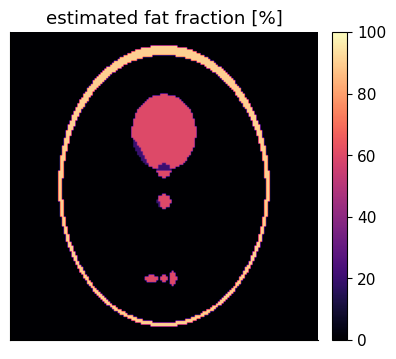

rim       : true FF  90.0 %, estimated  90.0 %
ellipse   : true FF  60.0 %, estimated  60.0 %
lesions   : true FF  20.0 %, estimated  20.0 %
WM-region : true FF   0.0 %, estimated   0.0 %


In [9]:
# Fat-fraction map from the phase-corrected reconstruction
w, f = recon["4 phase-corrected"]
ff_hat = np.where(M0 > 0, np.clip(f, 0, None) / (np.clip(w, 0, None) + np.clip(f, 0, None) + 1e-12), 0)
plt.figure(figsize=(4.5, 4))
mt.show_image(ff_hat * 100, title="estimated fat fraction [%]", cmap="magma", vmin=0, vmax=100, colorbar=True)
plt.show()
for k, name in [(1, "rim"), (3, "ellipse"), (5, "lesions"), (2, "WM-region")]:
    print(f"{name:10s}: true FF {FF[lab==k].mean()*100:5.1f} %, estimated {ff_hat[lab==k].mean()*100:5.1f} %")

*Interpretation:* with phase correction the fat fraction is recovered exactly in this idealized simulation; in vivo, $T_2^*$ decay between the echoes and the multi-peak fat spectrum bias two-point estimates, which is why quantitative PDFF protocols use 6 or more echoes.

> **⚠️ Common confusion:** in a **spin echo**, the 180° pulse refocuses the chemical-shift phase too, so at the spin-echo time fat and water are in phase whatever the TE. Spin-echo Dixon therefore shifts the readout slightly away from the spin echo ("asymmetric spin echo") to create the out-of-phase condition. See [D3](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb).

## 6. Fat suppression techniques (added)

Fat is bright on $T_1$-weighted and on fast-spin-echo $T_2$-weighted images and can hide edema, enhancement or lesions. Four families of methods remove it:

### 6.1 Spectral fat saturation (CHESS / "fat-sat")

Before each excitation (or every few), a **frequency-selective 90° pulse** centred at the fat frequency tips only fat into the transverse plane, and a **crusher gradient** dephases it. The imaging pulse that follows finds fat with $M_z\approx0$. The pulse must be narrow-band enough not to touch water, i.e. its bandwidth must be well below $|\Delta f_{cs}|$ – and the method fails wherever $\Delta f_r$ moves the fat peak out of (or the water peak into) the pulse's band.

The cell below simulates a Gaussian fat-sat pulse at 1.5 T (Bloch simulation over frequency) and shows $M_z$ after the pulse, with the water and fat peaks drawn for $\Delta f_r=0$ and for a local field error of +1.5 ppm (≈ +96 Hz).

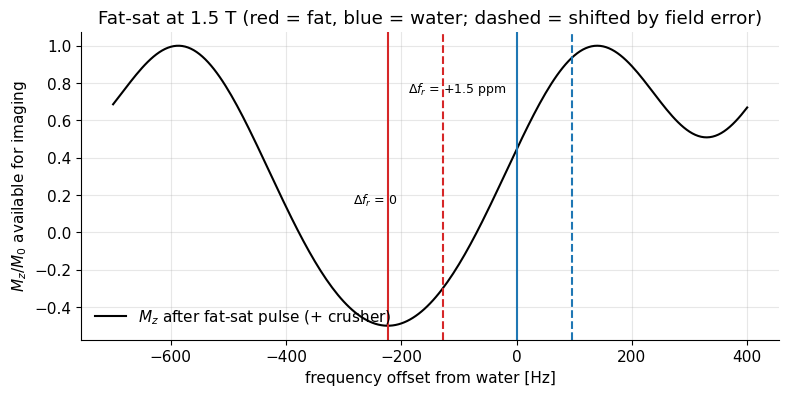

pulse duration 15 ms; Mz(fat) = -0.50, Mz(fat + 96 Hz) = -0.30, Mz(water) = 0.44


In [10]:
# Spectral fat saturation: Bloch simulation of a Gaussian 90-degree pulse centred on fat (1.5 T)
B0 = 1.5
dfcs = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)          # [Hz]
dt = 20e-6
sig_t = 2.5e-3                                     # Gaussian std in time [s] -> spectral std 1/(2 pi sig_t) ~ 64 Hz
tp = np.arange(-3 * sig_t, 3 * sig_t, dt)          # 15 ms pulse
b1 = np.exp(-tp**2 / (2 * sig_t**2)) * np.exp(-1j * 2 * np.pi * dfcs * tp)   # modulate to fat frequency
b1 *= (np.pi / 2) / mt.flip_angle(b1, dt)          # scale to 90 degrees on fat resonance
freqs = np.linspace(-700, 400, 221)
_, M = mt.bloch_simulate(B1=b1, dt=dt, df=freqs, return_all=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(freqs, M[:, 2], "k", label="$M_z$ after fat-sat pulse (+ crusher)")
for shift, ls, txt in [(0, "-", "Δf_r = 0"), (mt.ppm_to_hz(1.5, B0), "--", "Δf_r = +1.5 ppm")]:
    for f0, col, nm in [(0, "C0", "water"), (dfcs, "C3", "fat")]:
        ax.axvline(f0 + shift, color=col, ls=ls, lw=1.5)
    ax.text(dfcs + shift - 60, 0.15 + 0.6 * (shift > 0), txt.replace('Δf_r', r'$\Delta f_r$'), fontsize=9)
ax.set_xlabel("frequency offset from water [Hz]"); ax.set_ylabel(r"$M_z/M_0$ available for imaging")
ax.set_title(f"Fat-sat at {B0} T (red = fat, blue = water; dashed = shifted by field error)")
ax.legend(loc="lower left"); plt.show()
print(f"pulse duration {tp.ptp()*1e3:.0f} ms; Mz(fat) = {np.interp(dfcs, freqs, M[:,2]):.2f}, "
      f"Mz(fat + 96 Hz) = {np.interp(dfcs + 96, freqs, M[:,2]):.2f}, Mz(water) = {np.interp(0, freqs, M[:,2]):.2f}")

*Interpretation:* with a perfect field, fat ends at $M_z\approx0$ (suppressed) and water is untouched; with a +1.5 ppm field error the fat peak moves onto the edge of the band and is hardly suppressed at all (90 % left) – the familiar "failed fat-sat" patches near metal, at the neck or at the edge of the field of view. At 3 T the peaks are twice as far apart, which makes fat-sat easier, but field errors in Hz also double.

### 6.2 STIR

**STIR** (short-TI inversion recovery, [D1](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb)) nulls fat by its $T_1$: $TI\approx T_1^{fat}\ln2$ ≈ 150–180 ms at 1.5 T, 220–280 ms at 3 T. It is **insensitive to $B_0$ inhomogeneity** (it does not care about frequency), so it is the method of choice near metal and over large fields of view. Downsides: lower SNR (water has also only partly recovered at TI), longer scans, and it nulls every tissue with a fat-like $T_1$ – including gadolinium-enhanced tissue.

In [11]:
# STIR: what fraction of water (muscle) signal is left at the fat null point?
for B0, T1fat, T1mus in [(1.5, 0.26, 0.87), (3.0, 0.40, 1.41)]:
    TR = 4.0
    TI = T1fat * np.log(2 / (1 + np.exp(-TR / T1fat)))
    s_mus = mt.inversion_recovery_signal(TI, TR, 0, T1mus, 1.0)
    print(f"{B0} T: TI_null(fat) = {TI*1e3:.0f} ms; muscle signal = {s_mus:+.2f} M0 "
          f"(|.| = {abs(s_mus)*100:.0f} % of a fully relaxed scan)")

1.5 T: TI_null(fat) = 180 ms; muscle signal = -0.62 M0 (|.| = 62 % of a fully relaxed scan)
3.0 T: TI_null(fat) = 277 ms; muscle signal = -0.58 M0 (|.| = 58 % of a fully relaxed scan)


*Interpretation:* at the fat null, muscle is still inverted (negative) and gives only ~60 % of its relaxed signal in a magnitude image – the SNR price of STIR.

### 6.3 Water excitation (binomial pulses)

Instead of destroying fat, excite **only water**. A **1-1 binomial** pulse is two pulses of $\theta/2$ separated by $\tau=1/(2|\Delta f_{cs}|)$ (2.24 ms at 1.5 T, 1.12 ms at 3 T). Water sees two identical rotations that add to $\theta$. Fat precesses by exactly 180° between the pulses, so the second pulse rotates it *back* to the z-axis: no fat excitation. A **1-2-1** pulse ($\theta/4$, $\theta/2$, $\theta/4$ with spacing $\tau$) has a broader null around fat and is more robust to field errors.

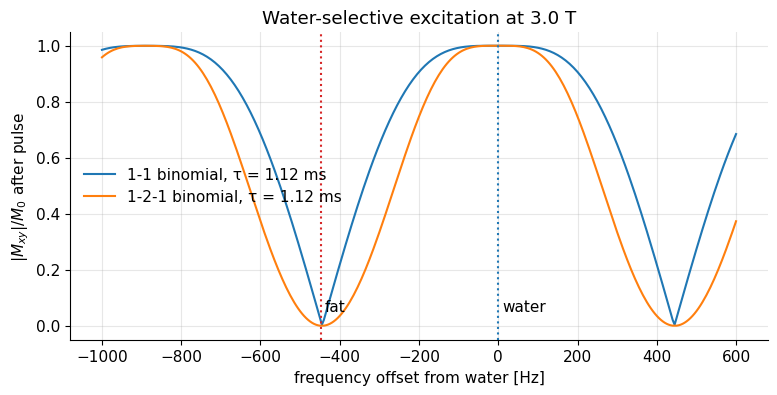

In [12]:
# Water excitation: frequency response of 1-1 and 1-2-1 binomial pulses (Bloch simulation, 3 T, 90 deg total)
B0 = 3.0
dfcs = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)
tau = 1 / (2 * abs(dfcs))                          # [s]
trf = 0.1e-3; dt = 10e-6                           # each sub-pulse 0.1 ms hard pulse
n_rf, n_gap = int(round(trf / dt)), int(round((tau - trf) / dt))
def binomial(weights, theta=np.pi / 2):
    b = []
    for i, wgt in enumerate(weights):
        b += [mt.b1_for_flip(theta * wgt / sum(weights), trf)] * n_rf
        if i < len(weights) - 1:
            b += [0.0] * n_gap
    return np.array(b, complex)
freqs = np.linspace(-1000, 600, 321)
plt.figure(figsize=(9, 4))
for wts, name in [((1, 1), "1-1"), ((1, 2, 1), "1-2-1")]:
    _, M = mt.bloch_simulate(B1=binomial(wts), dt=dt, df=freqs, return_all=False)
    plt.plot(freqs, np.hypot(M[:, 0], M[:, 1]), label=f"{name} binomial, τ = {tau*1e3:.2f} ms")
plt.axvline(0, color="C0", ls=":", lw=1.5); plt.text(10, 0.05, "water")
plt.axvline(dfcs, color="C3", ls=":", lw=1.5); plt.text(dfcs + 10, 0.05, "fat")
plt.xlabel("frequency offset from water [Hz]"); plt.ylabel(r"$|M_{xy}|/M_0$ after pulse")
plt.title(f"Water-selective excitation at {B0} T"); plt.legend(); plt.show()

*Interpretation:* both pulses give full excitation at water and zero at fat; the 1-2-1 null around fat is wider (more tolerant to field errors). Note the response is periodic in frequency with period $1/\tau$ = 894 Hz, a side effect of using a train of short pulses.

### 6.4 Comparison

| method | principle | robust to $B_0$ errors? | robust to $B_1^+$ errors? | SNR / time cost | compatible with Gd? |
|---|---|---|---|---|---|
| spectral fat-sat (CHESS) | saturate fat frequency | **no** | partly (flip error → residual fat) | small extra time, extra SAR | yes |
| STIR | null by $T_1$ | **yes** | needs good inversion (adiabatic) | big SNR loss, long TR | **no** |
| SPAIR / SPIR (hybrid) | fat-selective *adiabatic* inversion + TI | no | yes | moderate | yes |
| water excitation | excite water only | moderately | moderately | longer excitation → longer TR | yes |
| Dixon | separate by chemical-shift phase | yes (with field estimation) | yes | needs 2+ echoes; gives fat *and* water images | yes |

> **🔧 Engineering reality:** the fat-sat pulse must be centred on the actual fat frequency, so the scanner measures the water peak position (a quick spectrum, the "centre frequency" or "F0" calibration) for every patient. A wrong F0 – for example when a large fatty region dominates the spectrum and is mistaken for water – suppresses water instead of fat: a classic failure.

## 7. Contrast agents

MRI contrast agents work indirectly: they are not imaged themselves, they **shorten the relaxation times** ($T_1$, $T_2$, $T_2^*$) of the water around them – i.e. they **increase the relaxation rates**. (The original said they "shorten the relaxation rates"; it is the times that shorten.) The two classes are:

* **gadolinium (Gd) chelates** – Gd³⁺ has 7 unpaired electrons and is strongly paramagnetic; water molecules that briefly bind to it relax very efficiently. Free Gd³⁺ is toxic, so it is tightly bound in a chelate (linear or, more stable, macrocyclic). Mostly used for $T_1$ shortening ("positive" contrast, bright on $T_1$-weighted images).
* **iron-oxide particles** (SPIO/USPIO, ferumoxytol) – superparamagnetic, mainly $T_2$/$T_2^*$ shortening ("negative" contrast).

The effect is linear in concentration, characterized by the **relaxivities** $r_1$, $r_2$:

$$\frac{1}{\hat T_1}=\frac{1}{T_1}+r_1\,C,\qquad \frac{1}{\hat T_2}=\frac{1}{T_2}+r_2\,C .$$

*In words:* the agent adds a relaxation **rate** proportional to its concentration,
where $T_1$, $T_2$ are the tissue values without agent, $\hat T_1$, $\hat T_2$ the values with agent, $C$ the concentration in mmol/L (= mM), and $r_1$, $r_2$ the relaxivities in L mmol⁻¹ s⁻¹ (= mM⁻¹ s⁻¹). For common Gd chelates at 1.5 T, $r_1\approx$ 3–5 and $r_2\approx$ 4–6 mM⁻¹ s⁻¹ in plasma (Rohrer et al. 2005); $r_1$ decreases somewhat at higher field. The standard dose is 0.1 mmol per kg body weight.

> **📐 Math note:** a concentration of 0.5 mM with $r_1$ = 4 mM⁻¹ s⁻¹ adds a rate of 2 s⁻¹. For tissue with $T_1$ = 1 s ($R_1$ = 1 s⁻¹) the new rate is 3 s⁻¹, so $\hat T_1$ = 333 ms – a threefold shortening from a sub-millimolar concentration.

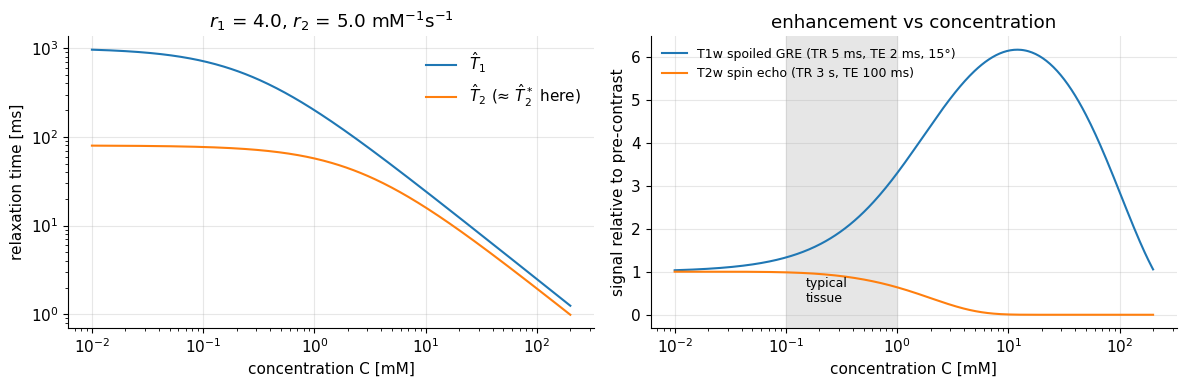

C =  0.1 mM: T1 =    713 ms, T2 =  76.9 ms, T1w GRE x1.33, T2w SE x0.99
C =  0.5 mM: T1 =    331 ms, T2 =  66.6 ms, T1w GRE x2.39, T2w SE x0.82
C =  1.0 mM: T1 =    198 ms, T2 =  57.0 ms, T1w GRE x3.31, T2w SE x0.63
C =  5.0 mM: T1 =     48 ms, T2 =  26.8 ms, T1w GRE x5.66, T2w SE x0.09
C = 50.0 mM: T1 =      5 ms, T2 =   3.8 ms, T1w GRE x4.65, T2w SE x0.00


In [13]:
# Effect of a Gd agent on T1, T2 and on T1-weighted (spoiled GRE) and T2-weighted (SE) signal
r1, r2 = 4.0, 5.0                  # relaxivities [L/(mmol s)] ~ Gd chelate at 1.5 T
T1_0, T2_0, M0 = 1.0, 0.08, 1.0    # tissue without agent [s]
C = np.concatenate([[0], np.logspace(-2, np.log10(200), 400)])   # concentration [mmol/L], 0 and 0.01-200
T1c = 1 / (1 / T1_0 + r1 * C); T2c = 1 / (1 / T2_0 + r2 * C)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].loglog(C[1:], T1c[1:] * 1e3, label=r"$\hat T_1$"); axs[0].loglog(C[1:], T2c[1:] * 1e3, label=r"$\hat T_2$ (≈ $\hat T_2^*$ here)")
axs[0].set_xlabel("concentration C [mM]"); axs[0].set_ylabel("relaxation time [ms]"); axs[0].legend()
axs[0].set_title(f"$r_1$ = {r1}, $r_2$ = {r2} mM$^{{-1}}$s$^{{-1}}$")
S_t1 = mt.spoiled_gre_signal(np.deg2rad(15), 0.002, 0.005, T1c, T2c, M0)     # 3D T1w GRE: TR 5 ms, TE 2 ms, 15 deg
S_t2 = mt.spin_echo_signal(0.100, 3.0, T1c, T2c, M0)                         # T2w SE
axs[1].semilogx(C[1:], S_t1[1:] / S_t1[0], label="T1w spoiled GRE (TR 5 ms, TE 2 ms, 15°)")
axs[1].semilogx(C[1:], S_t2[1:] / S_t2[0], label="T2w spin echo (TR 3 s, TE 100 ms)")
axs[1].set_xlabel("concentration C [mM]"); axs[1].set_ylabel("signal relative to pre-contrast")
axs[1].axvspan(0.1, 1.0, color="0.9", zorder=0); axs[1].text(0.15, 0.3, "typical\ntissue", fontsize=9)
axs[1].legend(fontsize=9); axs[1].set_title("enhancement vs concentration")
plt.tight_layout(); plt.show()
for c in [0.1, 0.5, 1.0, 5.0, 50.0]:
    i = np.argmin(abs(C - c))
    print(f"C = {c:4.1f} mM: T1 = {T1c[i]*1e3:6.0f} ms, T2 = {T2c[i]*1e3:5.1f} ms, "
          f"T1w GRE x{S_t1[i]/S_t1[0]:.2f}, T2w SE x{S_t2[i]/S_t2[0]:.2f}")

*Interpretation:* at tissue concentrations the $T_1$ effect dominates – the $T_1$-weighted signal multiplies several-fold while the short-TE gradient echo hardly feels the $T_2$ change. The enhancement saturates once $\hat T_1\ll TR/\theta^2$-ish (all tissue fully recovers each TR), and only at very high concentrations (tens of mM, e.g. concentrated agent in the bladder or a syringe) does $T_2^*$ shortening win and the signal drop. On the $T_2$-weighted spin echo the agent darkens tissue already at ~1 mM. In vivo, agent confined to vessels creates strong *mesoscopic* field disturbances, so the effective $r_2^*$ during a bolus passage is much larger than the in-vitro $r_2$ – the basis of DSC perfusion imaging (Section 8).

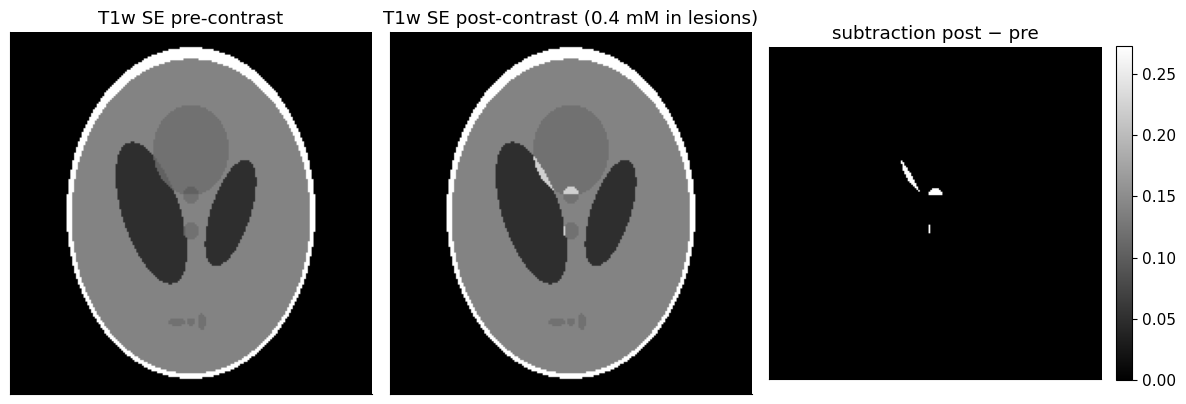

In [14]:
# Pre- and post-contrast T1-weighted spin echo of the phantom: only the 'lesions' (label 5) take up agent
ph = mt.tissue_phantom(192); lab = ph["labels"]
Cmap = np.where(lab == 5, 0.4, 0.0)                         # 0.4 mM in lesions (leaky blood-brain barrier)
T1post = 1 / (1 / ph["T1"] + r1 * Cmap); T2post = 1 / (1 / ph["T2"] + r2 * Cmap)
pre = mt.spin_echo_signal(0.015, 0.5, ph["T1"], ph["T2"], ph["M0"]) * (lab > 0)
post = mt.spin_echo_signal(0.015, 0.5, T1post, T2post, ph["M0"]) * (lab > 0)
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
mt.show_image(pre, ax=axs[0], title="T1w SE pre-contrast", vmin=0, vmax=pre.max())
mt.show_image(post, ax=axs[1], title="T1w SE post-contrast (0.4 mM in lesions)", vmin=0, vmax=pre.max())
mt.show_image(post - pre, ax=axs[2], title="subtraction post − pre", colorbar=True)
plt.tight_layout(); plt.show()

*Interpretation:* the small "lesions", nearly invisible before contrast, light up afterwards; subtraction isolates the enhancement. Compare with the real post-contrast example in [D4](../pass2_deep_dive/D4_Image_Contrast_Examples.ipynb).

> **🔧 Engineering reality / safety:** gadolinium agents are very safe for most patients, but in severe renal failure linear agents were linked to **nephrogenic systemic fibrosis** (NSF), and traces of Gd are retained in brain and bone after repeated doses. This has shifted practice to macrocyclic agents and the lowest effective dose. See [B6 MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb).

## 8. Other in vivo contrasts (brief preview)

The original chapter mentions that flow and magnetization transfer are further important sources of contrast. For orientation:

* **Diffusion:** with strong gradient pairs, randomly moving water loses phase coherence: $S=S_0e^{-bD}$, where $b$ (s/mm²) summarizes the gradient strength and timing and $D$ (mm²/s) is the diffusion coefficient. Free water at 37 °C has $D\approx3\times10^{-3}$ mm²/s, brain tissue ≈ 0.7–0.8×10⁻³, acute stroke (cytotoxic edema) ≈ 0.4×10⁻³ – bright on diffusion-weighted images within minutes of onset.
* **Perfusion:** dynamic susceptibility contrast (DSC: the $T_2^*$ drop during a Gd bolus), dynamic contrast-enhanced (DCE: $T_1$ enhancement over minutes), and arterial spin labelling (ASL: magnetically labelled blood water as an endogenous tracer, no injection).
* **Flow:** moving spins acquire phase in gradients (phase-contrast velocity mapping) and fresh unsaturated spins entering a slice are bright (time-of-flight angiography).
* **Magnetization transfer (MT):** protons bound to macromolecules have very short $T_2$ (invisible), but they exchange magnetization with free water; saturating them off-resonance reduces the water signal in a tissue-dependent way (e.g. myelin).

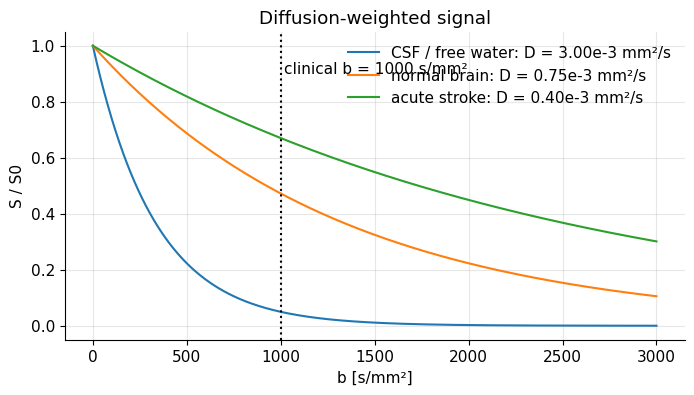

In [15]:
# Diffusion weighting: S/S0 = exp(-b D) for typical tissues
b = np.linspace(0, 3000, 300)             # [s/mm^2]
for name, D in [("CSF / free water", 3.0e-3), ("normal brain", 0.75e-3), ("acute stroke", 0.4e-3)]:
    plt.plot(b, np.exp(-b * D), label=f"{name}: D = {D*1e3:.2f}e-3 mm²/s")
plt.axvline(1000, color="k", ls=":"); plt.text(1020, 0.9, "clinical b = 1000 s/mm²")
plt.xlabel("b [s/mm²]"); plt.ylabel("S / S0"); plt.legend(); plt.title("Diffusion-weighted signal")
plt.show()

*Interpretation:* at b = 1000 s/mm², CSF is almost black (5 %), normal tissue keeps ~47 %, and stroke tissue ~67 %: restricted diffusion is bright.

## Key takeaways

* Field variations $\Delta f_r=\bar\gamma\Delta B_0$ come from the magnet and, mostly, from susceptibility differences in the body; chemical shift $\Delta f_{cs}=\delta_{cs}\bar\gamma B_0$ separates fat from water by −3.5 ppm (−223 Hz at 1.5 T, −447 Hz at 3 T).
* $T_2^*$ decay is the dephasing of many isochromats inside a voxel; the extra decay is the Fourier transform of the frequency distribution. Only a Lorentzian gives an exact exponential, $1/T_2^*=1/T_2+2\pi\Gamma$; $T_2^*$ depends on voxel size, shim and TE.
* Susceptibility contrast: phase (SWI, QSM) and $T_2^*$ reveal veins (deoxyhemoglobin), iron, blood products and calcium; BOLD fMRI measures a few-percent $T_2^*$ change, optimally at $TE\approx T_2^*$.
* Two-point Dixon: $\hat m_w=\tfrac12(s_{IP}+s_{OP})$, $\hat m_f=\tfrac12(s_{IP}-s_{OP})$, but field-induced phase must be corrected; magnitude-only Dixon swaps fat and water where fat > 50 %.
* Fat suppression: fat-sat (frequency, $B_0$-sensitive), STIR ($T_1$, robust but SNR-costly and not after Gd), water excitation (binomial pulses), Dixon (robust, gives both images).
* Contrast agents add relaxation **rates**: $1/\hat T_{1,2}=1/T_{1,2}+r_{1,2}C$; at tissue concentrations Gd brightens $T_1$-weighted images, at high concentrations $T_2^*$ shortening darkens.

## Check your understanding

**1.** Fat at 7 T: what is $\Delta f_{cs}$ and the first out-of-phase TE?

<details><summary>Answer</summary>

$\Delta f_{cs}=-3.5\times10^{-6}\cdot42.58\,\text{MHz/T}\cdot7\,\text{T}\approx-1043$ Hz. First OP TE $=0.5/1043$ Hz ≈ **0.48 ms** – so short that it is hard to reach; 7 T Dixon often uses other echo combinations.

</details>

**2.** A voxel has $T_2$ = 80 ms and a Lorentzian off-resonance distribution with half-width $\Gamma$ = 5 Hz. What is $T_2^*$?

<details><summary>Answer</summary>

$1/T_2'=2\pi\cdot5=31.4$ s⁻¹; $1/T_2^*=12.5+31.4=43.9$ s⁻¹ → $T_2^*\approx$ **22.8 ms**.

</details>

**3.** Why does the magnitude-based two-point Dixon put a voxel with 70 % fat into the "water" image?

<details><summary>Answer</summary>

$|s_{IP}|=w+f$ and $|s_{OP}|=|w-f|$. Then $(|s_{IP}|+|s_{OP}|)/2=\max(w,f)$ and $(|s_{IP}|-|s_{OP}|)/2=\min(w,f)$: the magnitude has lost the sign of $w-f$, so the method cannot tell which component is bigger. It always calls the bigger one "water".

</details>

**4.** A tissue has $T_1$ = 1200 ms. After Gd it contains 0.2 mM agent with $r_1$ = 4 mM⁻¹ s⁻¹. New $T_1$?

<details><summary>Answer</summary>

$1/\hat T_1 = 1/1.2+4\cdot0.2=0.833+0.8=1.633$ s⁻¹ → $\hat T_1\approx$ **612 ms**.

</details>

**5.** Near a hip prosthesis, which fat-suppression method would you choose and why?

<details><summary>Answer</summary>

**STIR** (or Dixon). Metal creates large $B_0$ errors that shift fat and water frequencies, so spectral fat-sat and water excitation fail; STIR nulls by $T_1$ and does not depend on frequency. (Gd-enhanced imaging would need Dixon instead, since STIR also nulls enhancing tissue.)

</details>

**6.** Why is the optimal BOLD echo time approximately $T_2^*$?

<details><summary>Answer</summary>

The absolute signal change is $\Delta S\propto TE\,e^{-TE/T_2^*}$ (relative change ∝ TE times a decaying signal). Its derivative $e^{-TE/T_2^*}(1-TE/T_2^*)$ vanishes at $TE=T_2^*$.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "In Vivo Contrast Mechanisms". Changes: Python port of `t2star_spinecho_illustration.m`; added frequency-distribution ↔ decay derivation (Lorentzian/Gaussian/uniform), voxel-size dependence, synthetic SWI, BOLD model and time course, two-point Dixon implementation with failure modes and fat-fraction map, fat-suppression section (fat-sat, STIR, binomial water excitation, comparison), relaxivity calculations and phantom enhancement, diffusion preview; corrected the Dixon factor ½, the missing $t$ in the $T_2^*$ phase term, "shorten the relaxation rates" (→ times) and typos.*